In [59]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

In [60]:
df = pd.read_csv(r"D:\data_cience\DSEA\kenya_food_2\data\food_prices_kenya.csv")

df.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94


In [61]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2742 entries, 0 to 2741
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        2742 non-null   str    
 1   region      2683 non-null   str    
 2   county      2683 non-null   str    
 3   market      2742 non-null   str    
 4   commodity   2742 non-null   str    
 5   price_type  2742 non-null   str    
 6   unit        2742 non-null   str    
 7   price_kes   2742 non-null   float64
 8   price_usd   2742 non-null   float64
dtypes: float64(2), str(7)
memory usage: 192.9 KB


In [62]:
df.sample(50)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
1439,2017-09-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,8820.00,85.63
527,2015-06-15,Coast,Kilifi,Kilifi,Maize,Retail,KG,36.00,0.37
2653,2017-07-15,Nairobi,Nairobi,Nairobi,Maize,Wholesale,90 KG,4320.00,41.59
1712,2012-11-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,4830.00,56.52
2233,2009-11-15,Nyanza,Kisumu,Kisumu,Maize,Wholesale,90 KG,2400.00,32.20
2104,2013-01-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,2642.00,30.47
1524,2010-11-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,4990.00,62.06
2654,2017-08-15,Nairobi,Nairobi,Nairobi,Maize,Wholesale,90 KG,3656.00,35.29
1814,2007-08-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,3148.00,47.20
1542,2012-05-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,8000.00,95.24


In [63]:
#convert date column to real dates
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
781,2008-09-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,45.0,0.63
1250,2015-09-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,51.4,0.49
2403,2010-04-15,Coast,Mombasa,Mombasa,Maize,Wholesale,90 KG,1821.0,23.77
1947,2018-10-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,6087.5,60.45
329,2018-09-15,Rift Valley,Baringo,Marigat,Beans,Retail,KG,103.0,1.02


In [64]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

df.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
1266,2017-03-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,46.6,0.45,2017,3
44,2018-10-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,75.0,0.74,2018,10
1617,2018-09-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,5925.0,58.76,2018,9
371,2017-04-15,North Eastern,Garissa,Garissa,Maize,Retail,KG,60.0,0.58,2017,4
2680,2019-10-15,Nairobi,Nairobi,Nairobi,Maize,Wholesale,90 KG,3743.0,36.11,2019,10


In [65]:
#find the rows where county is missing
nulls = (
    df[df["county"].isna()]          # keep only rows where county is missing
    .groupby("market")
    .size()
    .sort_values(ascending=False)
)
print(nulls)

market
Hola    59
dtype: int64


In [66]:
#fill the missing county and region for the market that has none
# df["county"].isna().sum()
# df["region"].isna().sum()
mask = df["market"] == "Hola"
df.loc[mask, ["county", "region"]] = ["Tana River", "Coast"]


In [67]:
df.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
1667,2009-01-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,4045.0,50.63,2009,1
778,2008-06-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,50.0,0.78,2008,6
76,2016-07-15,Coast,Kilifi,Kilifi,Beans,Retail,KG,89.0,0.88,2016,7
116,2019-11-15,Coast,Kilifi,Kilifi,Beans,Retail,KG,113.2,1.11,2019,11
709,2016-09-15,Eastern,Kitui,Kitui,Maize,Retail,KG,34.0,0.34,2016,9


In [68]:
# Fill the missing county and region for Hola market
# Hola is located in Tana River county within the Coast region
df.loc[df['market'] == 'Hola', 'county'] = df.loc[df['market'] == 'Hola', 'county'].fillna('Tana River')
df.loc[df['market'] == 'Hola', 'region'] = df.loc[df['market'] == 'Hola', 'region'].fillna('Coast')

In [69]:
#sorting the date from the earliest to the latest date
highest_date = df["date"].max()
print(highest_date)
lowest_date = df["date"].min()
print(lowest_date)

2019-12-15 00:00:00
2006-01-15 00:00:00


In [70]:
#we are finding the price for a single kg of maize by divinding the wholesale price by 90 ---> retail_price
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"] / 90, df["price_kes"])

In [71]:
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy()
df_wholesale.head()


,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
1300,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2799.0,38.93,2006,1,31.100000
1301,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3150.0,43.93,2006,2,35.000000
1302,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3305.0,45.68,2006,3,36.722222
1303,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3060.0,43.05,2006,4,34.000000
1304,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3311.0,46.18,2006,5,36.788889


In [72]:
# this code splits the dataset into a retail-only dataframe
df_retail = df[(df["price_type"] == "Retail") & (df["unit"] == "KG")].copy()
df_retail.head()


,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1,87.3
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2,81.9
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3,82.2
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4,85.0
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5,90.0


In [73]:
#average for the maize commodity in the wholesale sales_price_per_kg
df_wholesale.loc[df_wholesale["commodity"] == "Maize", "price_per_kg"].mean()

np.float64(28.54230389890584)

In [74]:
#average for the maize commodity in the retail sales_price_per_kg
df_retail.loc[df_retail["commodity"] == "Maize", "price_per_kg"].mean()

np.float64(47.91992670157068)

In [75]:
df.loc[df["date"] == "2006-01-15"]

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
118,2006-01-15,Eastern,Kitui,Kitui,Beans,Retail,KG,39.0,0.54,2006,1,39.000000
581,2006-01-15,Eastern,Kitui,Kitui,Maize,Retail,KG,17.0,0.24,2006,1,17.000000
749,2006-01-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,26.0,0.36,2006,1,26.000000
915,2006-01-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,30.0,0.42,2006,1,30.000000
1138,2006-01-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,21.0,0.29,2006,1,21.000000
1300,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2799.0,38.93,2006,1,31.100000
1467,2006-01-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,4000.0,55.63,2006,1,44.444444
1631,2006-01-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,3246.0,45.15,2006,1,36.066667
1795,2006-01-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,3175.0,44.16,2006,1,35.277778
2021,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1192.0,16.58,2006,1,13.244444


In [76]:
df_maize = df[(df["commodity"] == "Maize") & (df["price_type"] == "Wholesale")].copy().round(2)
df_maize.head(5)

C:\Users\R!CKY 3\AppData\Local\Temp\ipykernel_21956\2941648154.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  df_maize = df[(df["commodity"] == "Maize") & (df["price_type"] == "Wholesale")].copy().round(2)


,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
2021,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1192.00,16.58,2006,1,13.24
2022,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1304.00,18.19,2006,2,14.49
2023,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1162.22,16.06,2006,3,12.91
2024,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1277.00,17.96,2006,4,14.19
2025,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1445.26,20.16,2006,5,16.06


In [77]:
#year over year average
yearly_avg = df_maize.groupby("year")["price_kes"].mean().reset_index().round(2)
yearly_avg

,year,price_kes
0,2006,1395.04
1,2007,1207.45
2,2008,1906.32
3,2009,2513.27
4,2010,1773.95
5,2011,3020.22
6,2012,3173.78
7,2013,2962.46
8,2014,2993.72
9,2015,2690.15


In [78]:
yearly_avg.columns = ["year", "avg_price_kes"]
yearly_avg

,year,avg_price_kes
0,2006,1395.04
1,2007,1207.45
2,2008,1906.32
3,2009,2513.27
4,2010,1773.95
5,2011,3020.22
6,2012,3173.78
7,2013,2962.46
8,2014,2993.72
9,2015,2690.15


In [79]:
yearly_avg["yoy_change_kes"] = yearly_avg["avg_price_kes"].diff()
yearly_avg


,year,avg_price_kes,yoy_change_kes
0,2006,1395.04,NaN
1,2007,1207.45,-187.59
2,2008,1906.32,698.87
3,2009,2513.27,606.95
4,2010,1773.95,-739.32
5,2011,3020.22,1246.27
6,2012,3173.78,153.56
7,2013,2962.46,-211.32
8,2014,2993.72,31.26
9,2015,2690.15,-303.57


In [80]:
#plotting the yearly average
# x axis = year
#y axis = avg_price_kes

In [81]:
y_values = yearly_avg["avg_price_kes"]
x_values = yearly_avg["year"] 

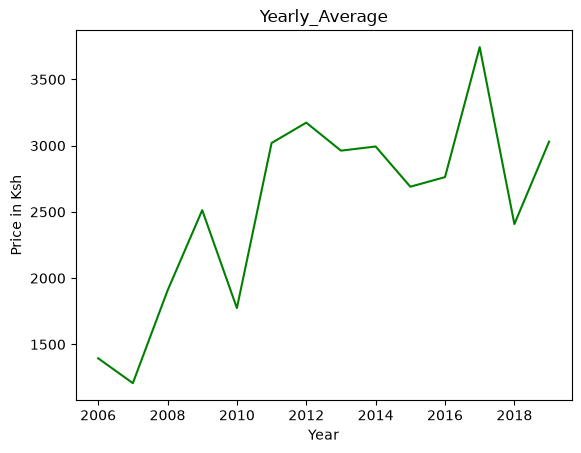

In [82]:
plt.plot(x_values, y_values, color= "green")
plt.title("Yearly_Average")
plt.xlabel("Year")
plt.ylabel("Price in Ksh")
plt.show()

In [83]:
yearly_avg.loc[yearly_avg['yoy_change_kes'].idxmax(), 'year'] # highest rise
yearly_avg.loc[yearly_avg['yoy_change_kes'].idxmin(), 'year'] #highest fall

np.int32(2018)

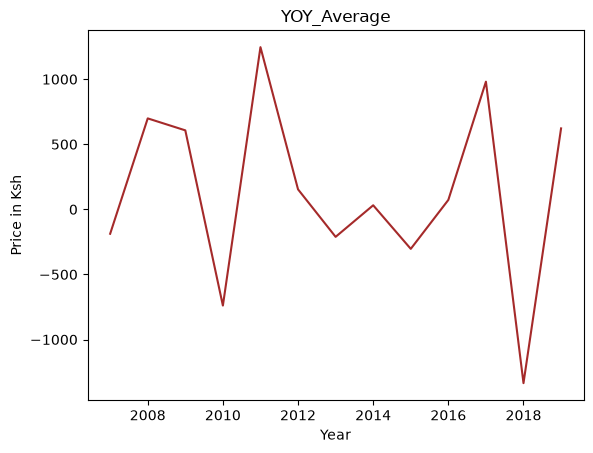

In [84]:
y_values = yearly_avg["yoy_change_kes"]
x_values = yearly_avg["year"]
plt.plot(x_values, y_values, color= "brown")
plt.title("YOY_Average")
plt.xlabel("Year")
plt.ylabel("Price in Ksh")
plt.show()

In [85]:
#Monthly of month average
monthly_avg = df_maize.groupby("month")["price_kes"].mean().reset_index().round(2)
monthly_avg

,month,price_kes
0,1,2329.52
1,2,2405.34
2,3,2449.26
3,4,2626.68
4,5,2823.53
5,6,2839.47
6,7,2833.00
7,8,2695.38
8,9,2539.27
9,10,2442.57


In [86]:
#rename the price_kes to avg_monthly_kes 
monthly_avg.columns = ["month", "avg_monthly_kes"]
monthly_avg.columns

Index(['month', 'avg_monthly_kes'], dtype='str')

In [87]:
#cheapest on average
cheapest_avg = monthly_avg.loc[monthly_avg["avg_monthly_kes"].idxmin()]   #this gives the index of the cheapest month [1] - January
cheapest_avg

month                 1.00
avg_monthly_kes    2329.52
Name: 0, dtype: float64

In [88]:
# dearest month
dearest_avg = monthly_avg.loc[monthly_avg["avg_monthly_kes"].idxmax(), 'month']   #this gives the index of the dearest month [6] - June
dearest_avg

np.int32(6)

In [89]:
# compare each market's January and June price, year by year, to see how often storing maize for five months paid off.
# here we first extract data from the said columns)jan and june afterwards merge them)
jan_data = df_maize[df_maize['month'] == 1][["market",'year', 'price_kes']]
june_data = df_maize[df_maize['month'] == 6][["market",'year', 'price_kes']]

# merge them side by side matching market and year, the suffixes are used to indicate which price belongs to wwhich month
merged_df = pd.merge(jan_data, june_data, on=["market", "year"], suffixes=("_jan", "_june"))
merged_df
# compare each market's January and June price, year by year, to see how often storing maize for five months paid off.
merged_df["gain_price"] = merged_df["price_kes_june"] - merged_df["price_kes_jan"]
merged_df["profitable_gain"] = merged_df["gain_price"] > 0
merged_df.head(10)


,market,year,price_kes_jan,price_kes_june,gain_price,profitable_gain
0,Eldoret,2006,1192.0,1549.00,357.00,True
1,Eldoret,2007,947.5,1204.71,257.21,True
2,Eldoret,2008,1200.0,1776.00,576.00,True
3,Eldoret,2009,1743.0,2776.00,1033.00,True
4,Eldoret,2010,2142.0,1556.00,-586.00,False
5,Eldoret,2011,1390.0,3800.00,2410.00,True
6,Eldoret,2012,2800.0,2960.00,160.00,True
7,Eldoret,2013,2642.0,2710.00,68.00,True
8,Eldoret,2014,2794.0,3100.00,306.00,True
9,Eldoret,2015,2000.0,2550.00,550.00,True


In [90]:
#In what share of market-years was the June price higher than the January price, and what was the median gain?
total_combinations = len(merged_df)
total_combinations
profitable_combination = merged_df["profitable_gain"].sum()
profitable_combination
profitable_market_share = ((profitable_combination/total_combinations) * 100).round(2)
profitable_market_share

# calculate the median gain
median_gain = merged_df["gain_price"].median()
median_gain
print(f"Total profitable markets are {profitable_combination}")
print(f"Profitable market is {profitable_market_share}%")
print(f"The median gain is Kes {median_gain}")


Total profitable markets are 44
Profitable market is 73.33%
The median gain is Kes 356.0


#### What costs and risks of storing maize does this calculation leave out
Storage losses: cost of hiring the storage, weevils, the larger grain borer, rodents, moisture and mould. Aflatoxin can make maize unsellable.
Weight loss as the grain dries out in store.
Theft.
Price risk: government actions (NCPB buying prices, duty-free imports) and good harvests in the region can push June prices down. In 1 in 4 market-years June was cheaper than January.
Farm-gate vs market prices: these are wholesale market prices, but farmers usually sell to traders for less.
Storage costs: bags (hermetic bags), chemicals, a store or silo, and transport to market.
The cost of waiting: the farmer may need cash at harvest for school fees, debts or inputs, and may have to borrow at interest.


In [91]:
wholesale_maize_month = df_maize[(df_maize["commodity"] == "Maize") & (df_maize["price_type"] == "Wholesale")].copy()
wholesale_maize_month.head(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
2021,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1192.00,16.58,2006,1,13.24
2022,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1304.00,18.19,2006,2,14.49
2023,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1162.22,16.06,2006,3,12.91
2024,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1277.00,17.96,2006,4,14.19
2025,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1445.26,20.16,2006,5,16.06


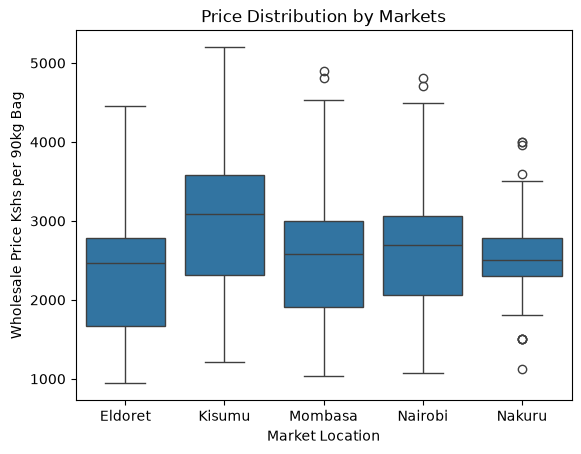

In [92]:
#we plot the box plot for visualizing outliers
sns.boxplot(data=df_maize, x="market", y="price_kes")
plt.title("Price Distribution by Markets")
plt.ylabel("Wholesale Price Kshs per 90kg Bag")
plt.xlabel("Market Location")
plt.show()

In [96]:
df_maize["price_kes"].describe()

count     721.000000
mean     2568.807351
std       849.836482
min       944.210000
25%      1989.000000
50%      2605.000000
75%      3100.000000
max      5200.000000
Name: price_kes, dtype: float64

In [ ]:
# 1. Filter for Retail Maize between 2015 and 2019
df_retail = df[
    (df["commodity"].str.lower() == "maize") & 
    (df["price_type"].str.lower() == "retail") & 
    (df["year"].between(2015, 2019))
].copy()

# 2. Get the Overall Average (2015-2019 combined) to find the absolute cheapest/most expensive
overall_avg = df_retail.groupby("market")["price_kes"].mean().sort_values(ascending=False).reset_index()
print("--- OVERALL AVERAGE PRICES (2015-2019) ---")
print(overall_avg.round(2))

# 3. Get the Yearly Averages and Rank them within each year
yearly_market_avg = df_retail.groupby(["year", "market"])["price_kes"].mean().reset_index()

# Create a ranking column where 1 is the most expensive market for that specific year
yearly_market_avg["rank"] = yearly_market_avg.groupby("year")["price_kes"].rank(ascending=False, method="min")

# 4. View the rankings side-by-side
rankings_pivot = yearly_market_avg.pivot(index="market", columns="year", values="rank")
print("\n--- MARKET RANKINGS BY YEAR (1 = Most Expensive) ---")
print(rankings_pivot)


--- OVERALL AVERAGE PRICES (2015-2019) ---
     market  price_kes
0    Lodwar      75.85
1   Mandera      67.53
2   Garissa      59.73
3   Kajiado      50.88
4      Hola      49.87
5  Marsabit      47.50
6   Marigat      46.53
7    Kilifi      43.84
8     Kitui      36.19

--- MARKET RANKINGS BY YEAR (1 = Most Expensive) ---
year      2015  2016  2017  2018  2019
market                                
Garissa    3.0   3.0   4.0   3.0   2.0
Hola       7.0   4.0   5.0   4.0   4.0
Kajiado    5.0   5.0   3.0   5.0   5.0
Kilifi     8.0   8.0   7.0   7.0   8.0
Kitui      9.0   9.0   9.0   9.0   9.0
Lodwar     1.0   1.0   1.0   1.0   3.0
Mandera    2.0   2.0   2.0   2.0   1.0
Marigat    6.0   7.0   6.0   8.0   6.0
Marsabit   4.0   6.0   8.0   6.0   7.0


In [97]:
# Which markets ranked in the top three every single year?
top3_every_year = rankings_pivot[(rankings_pivot <= 3).all(axis=1)].index.tolist()
print("Most expensive market:", overall_avg.iloc[0]["market"])
print("Cheapest market:", overall_avg.iloc[-1]["market"])
print("Top three every year:", top3_every_year)

Most expensive market: Lodwar
Cheapest market: Kitui
Top three every year: ['Lodwar', 'Mandera']


##### Answers: where households pay most (retail maize, 2015-2019)
- *Most expensive on average:* Lodwar, KES 75.85 per kg.
- *Cheapest on average:* Kitui, KES 36.19 per kg. Households in Lodwar paid about twice as much as households in Kitui.
- _Top three every year:_ Lodwar and Mandera. Garissa came close but fell to 4th in 2017.